# CardioIA Fase 4: Ir Além 1, ética e governança em Visão Computacional

**Curso:** Inteligência Artificial, FIAP, turma 2TIAOR, Fase 4, Cap 1
**Autor:** Silvio Prestes Guerreiro Junior, RM 567958

> **Aviso:** protótipo acadêmico, sem validade diagnóstica.

## Objetivo

1. Identificar limitações do dataset (desbalanceamento e representatividade).
2. Medir se o modelo do protótipo (ResNet50) erra de forma desigual entre grupos de pacientes, com métricas de fairness por **sexo**, **faixa etária** e **posição de aquisição**.
3. Testar uma prática de mitigação e discutir as implicações.

Nenhum modelo é treinado aqui. O notebook usa as previsões gravadas pelos notebooks `02` e `03` e o manifesto gerado no `01`.

**Métricas usadas.** Para cada grupo: recall (taxa de verdadeiros positivos), taxa de falsos negativos (FNR = 1 - recall), taxa de falsos positivos (FPR), precisão, taxa de seleção (fração classificada como positiva) e AUC. Para comparar grupos:

- **diferença de igualdade de oportunidade:** maior diferença de recall entre os grupos. Em triagem é a mais importante, porque mede se a doença passa despercebida mais em um grupo do que em outro;
- **diferença de odds equalizadas:** o maior valor entre a diferença de recall e a diferença de FPR;
- **diferença de paridade demográfica:** maior diferença na taxa de seleção.

Valor 0 significa tratamento igual. Os intervalos de confiança de 95% vêm de bootstrap sobre pacientes (2.000 repetições).

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

SEED = 42
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_PRINT = RAIZ / "prints"
ORDEM_FAIXA = ["0-17", "18-39", "40-59", "60+"]

man = pd.read_csv(RAIZ / "data" / "manifesto.csv")
meta = pd.read_csv(RAIZ / "data" / "raw" / "Data_Entry_2017_v2020.csv")
cfg = __import__("json").loads((RAIZ / "app" / "config.json").read_text())
LIMIAR = cfg["limiar_padrao"]

def carregar(split, modelo):
    p = pd.read_csv(RAIZ / "data" / f"pred_{split}_{modelo}.csv")
    d = p.merge(man[["arquivo", "paciente", "idade", "faixa", "sexo", "visao"]], on="arquivo")
    assert len(d) == len(p)
    return d

teste, val = carregar("teste", "resnet50"), carregar("val", "resnet50")
teste_cnn = carregar("teste", "cnn_do_zero")
print("Teste:", len(teste), "imagens,", teste.paciente.nunique(), "pacientes | limiar:", LIMIAR)

Teste: 819 imagens, 652 pacientes | limiar: 0.5


## 1. Limitações do dataset

### 1.1 Representatividade: quem está no dataset

In [2]:
meta["faixa"] = pd.cut(meta["Patient Age"], [0, 18, 40, 60, 200], labels=ORDEM_FAIXA, right=False).astype(str)
meta["cardio"] = meta["Finding Labels"].str.contains("Cardiomegaly")
linhas = []
for nome, col in [("sexo", "Patient Gender"), ("faixa", "faixa"), ("visao", "View Position")]:
    for g, sub in meta.groupby(col):
        linhas.append({"atributo": nome, "grupo": g, "imagens": len(sub), "% do dataset": round(len(sub) / len(meta) * 100, 1),
                       "% com cardiomegalia": round(sub.cardio.mean() * 100, 2)})
rep = pd.DataFrame(linhas).set_index(["atributo", "grupo"])
print("Dataset completo: 112.120 imagens. Prevalência geral de cardiomegalia:", round(meta.cardio.mean() * 100, 2), "%")
rep

Dataset completo: 112.120 imagens. Prevalência geral de cardiomegalia: 2.48 %


imagens  % do dataset  % com cardiomegalia
atributo grupo                                            
sexo     F        48780          43.5                 3.01
         M        63340          56.5                 2.06
faixa    0-17      5402           4.8                 2.80
         18-39    31037          27.7                 2.54
         40-59    49243          43.9                 2.32
         60+      26438          23.6                 2.63
visao    AP       44810          40.0                 2.71
         PA       67310          60.0                 2.32

A tabela seguinte mostra o tamanho das amostras do conjunto de teste que sustentam cada métrica. As imagens positivas se repetem por paciente, e imagens do mesmo paciente não são independentes. Por isso a tabela traz o número de pacientes além do número de imagens. As imagens negativas são uma por paciente.

In [3]:
# Composição do conjunto de teste por grupo e classe (tamanho das amostras que sustentam cada métrica)
pos, neg = teste[teste.y == 1], teste[teste.y == 0]
assert teste.groupby("paciente").y.nunique().max() == 1      # cada paciente tem imagens de uma só classe
print(f"Positivas: {len(pos)} imagens de {pos.paciente.nunique()} pacientes | negativas: {len(neg)} imagens de {neg.paciente.nunique()} pacientes")
for a in ["sexo", "faixa", "visao"]:
    v = teste.groupby("paciente")[a].nunique(); m = v[v > 1].index
    print(f"Pacientes com mais de um valor de {a}: {len(m)} ({int(teste.paciente.isin(m).sum())} imagens)")
comp = []
for a in ["sexo", "faixa", "visao"]:
    for g, s in teste.groupby(a):
        comp.append({"atributo": a, "grupo": g, "imagens": len(s), "pacientes": s.paciente.nunique(), "positivas": int(s.y.sum()),
                     "pacientes com positivas": s[s.y == 1].paciente.nunique(), "negativas": int((1 - s.y).sum()), "% positivas": round(s.y.mean() * 100, 1)})
pd.DataFrame(comp).set_index(["atributo", "grupo"])

Positivas: 402 imagens de 235 pacientes | negativas: 417 imagens de 417 pacientes
Pacientes com mais de um valor de sexo: 0 (0 imagens)
Pacientes com mais de um valor de faixa: 2 (4 imagens)
Pacientes com mais de um valor de visao: 27 (116 imagens)


imagens  pacientes  positivas  pacientes com positivas  \
atributo grupo                                                           
sexo     F          430        371        186                      127   
         M          389        281        216                      108   
faixa    0-17        41         29         18                        6   
         18-39      237        179        127                       69   
         40-59      342        280        154                       92   
         60+        199        166        103                       70   
visao    AP         379        283        192                       96   
         PA         440        396        210                      166   

                negativas  % positivas  
atributo grupo                          
sexo     F            244         43.3  
         M            173         55.5  
faixa    0-17          23         43.9  
         18-39        110         53.6  
         40-59        188         45.0  
         60+           96         51.8  
visao    AP           187         50.7  
         PA           230         47.7

### 1.2 Outras limitações (não mensuráveis com os dados disponíveis)

- **Sem raça, etnia ou condição socioeconômica.** O dataset não traz esses atributos, portanto não é possível medir viés em relação a eles. A ausência de medida não é ausência de viés.
- **Um único hospital.** Todas as imagens vêm do NIH Clinical Center (Estados Unidos), um hospital de pesquisa cujos pacientes não representam a população geral, muito menos a brasileira.
- **Rótulos com ruído.** Foram extraídos dos laudos por processamento de linguagem natural. Se o ruído for diferente entre grupos (por exemplo, laudos de pacientes acamados descritos de outra forma), as métricas por grupo herdam essa distorção.
- **Balanceamento artificial.** O subconjunto usado tem 50% de positivos, pareados por sexo, faixa etária e posição. Isso igualou a composição das classes, mas não corresponde à prevalência real.

## 2. Métricas de fairness por subgrupo (ResNet50, conjunto de teste)

In [4]:
def metricas(d, limiar=LIMIAR):
    y, yp = d.y.values, (d.prob.values >= limiar).astype(int)
    tp, fn, fp, tn = ((y == 1) & (yp == 1)).sum(), ((y == 1) & (yp == 0)).sum(), ((y == 0) & (yp == 1)).sum(), ((y == 0) & (yp == 0)).sum()
    return {"recall": tp / max(tp + fn, 1), "fnr": fn / max(tp + fn, 1), "fpr": fp / max(fp + tn, 1),
            "precisao": tp / max(tp + fp, 1), "selecao": yp.mean(),
            "auc": roc_auc_score(y, d.prob.values) if 0 < y.sum() < len(y) else np.nan, "fn": int(fn), "fp": int(fp)}

def bootstrap(d, atributo, limiar=LIMIAR, n=2000, limiares_grupo=None):
    # reamostra pacientes; devolve métricas por grupo e as diferenças entre grupos em cada repetição
    rng = np.random.default_rng(SEED)
    idx_pac = {k: g.index.values for k, g in d.groupby("paciente")}
    pacs = np.array(list(idx_pac)); grupos = sorted(d[atributo].unique(), key=lambda g: ORDEM_FAIXA.index(g) if g in ORDEM_FAIXA else g)
    reps, difs = {g: [] for g in grupos}, []
    for _ in range(n):
        s = d.loc[np.concatenate([idx_pac[k] for k in rng.choice(pacs, len(pacs), replace=True)])]
        m = {g: metricas(s[s[atributo] == g], limiares_grupo[g] if limiares_grupo else limiar) for g in grupos}
        for g in grupos: reps[g].append(m[g])
        r, f, se = [m[g]["recall"] for g in grupos], [m[g]["fpr"] for g in grupos], [m[g]["selecao"] for g in grupos]
        difs.append({"dif_recall": max(r) - min(r), "dif_fpr": max(f) - min(f), "dif_selecao": max(se) - min(se)})
    return grupos, {g: pd.DataFrame(v) for g, v in reps.items()}, pd.DataFrame(difs)

def tabela(d, atributo, limiar=LIMIAR, limiares_grupo=None):
    grupos, reps, difs = bootstrap(d, atributo, limiar, limiares_grupo=limiares_grupo)
    linhas = []
    for g in grupos:
        s = d[d[atributo] == g]; m = metricas(s, limiares_grupo[g] if limiares_grupo else limiar)
        ic = lambda c: f"{m[c]:.3f} [{reps[g][c].quantile(.025):.3f}, {reps[g][c].quantile(.975):.3f}]"
        linhas.append({"grupo": g, "n": len(s), "positivas": int(s.y.sum()), "recall": ic("recall"), "FNR": f"{m['fnr']:.3f}", "FPR": ic("fpr"),
                       "precisao": f"{m['precisao']:.3f}", "selecao": f"{m['selecao']:.3f}", "AUC": ic("auc"), "FN": m["fn"], "FP": m["fp"]})
    ms = {g: metricas(d[d[atributo] == g], limiares_grupo[g] if limiares_grupo else limiar) for g in grupos}
    obs = {"dif_recall": max(v["recall"] for v in ms.values()) - min(v["recall"] for v in ms.values()),
           "dif_fpr": max(v["fpr"] for v in ms.values()) - min(v["fpr"] for v in ms.values()),
           "dif_selecao": max(v["selecao"] for v in ms.values()) - min(v["selecao"] for v in ms.values())}
    return pd.DataFrame(linhas).set_index("grupo"), obs, difs, ms

resumo, por_grupo = [], {}
for a in ["sexo", "faixa", "visao"]:
    t, obs, difs, ms = tabela(teste, a); por_grupo[a] = ms
    print(f"\n=== {a.upper()} ==="); print(t.to_string())
    resumo.append({"atributo": a, "igualdade de oportunidade (dif. recall)": round(obs["dif_recall"], 3),
                   "dif. FPR": round(obs["dif_fpr"], 3), "odds equalizadas": round(max(obs["dif_recall"], obs["dif_fpr"]), 3),
                   "paridade demografica (dif. selecao)": round(obs["dif_selecao"], 3)})
resumo = pd.DataFrame(resumo).set_index("atributo")
resumo.to_csv(RAIZ / "data" / "fairness_resumo.csv")
resumo


=== SEXO ===
         n  positivas                recall    FNR                   FPR precisao selecao                   AUC  FN  FP
grupo                                                                                                                  
F      430        186  0.866 [0.812, 0.911]  0.134  0.246 [0.194, 0.300]    0.729   0.514  0.874 [0.837, 0.907]  25  60
M      389        216  0.866 [0.805, 0.915]  0.134  0.254 [0.187, 0.322]    0.810   0.594  0.888 [0.848, 0.924]  29  44



=== FAIXA ===
         n  positivas                recall    FNR                   FPR precisao selecao                   AUC  FN  FP
grupo                                                                                                                  
0-17    41         18  0.667 [0.429, 0.882]  0.333  0.435 [0.227, 0.643]    0.545   0.537  0.659 [0.467, 0.851]   6  10
18-39  237        127  0.882 [0.815, 0.937]  0.118  0.218 [0.143, 0.299]    0.824   0.574  0.890 [0.837, 0.934]  15  24
40-59  342        154  0.857 [0.785, 0.911]  0.143  0.234 [0.177, 0.297]    0.750   0.515  0.898 [0.857, 0.930]  22  44
60+    199        103  0.893 [0.820, 0.952]  0.107  0.271 [0.183, 0.364]    0.780   0.593  0.866 [0.804, 0.915]  11  26



=== VISAO ===
         n  positivas                recall    FNR                   FPR precisao selecao                   AUC  FN  FP
grupo                                                                                                                  
AP     379        192  0.880 [0.821, 0.927]  0.120  0.273 [0.211, 0.338]    0.768   0.580  0.880 [0.838, 0.916]  23  51
PA     440        210  0.852 [0.804, 0.899]  0.148  0.230 [0.177, 0.287]    0.772   0.527  0.883 [0.849, 0.915]  31  53


,igualdade de oportunidade (dif. recall),dif. FPR,odds equalizadas,paridade demografica (dif. selecao)
atributo,,,,
sexo,0.000,0.008,0.008,0.080
faixa,0.227,0.217,0.227,0.078
visao,0.028,0.042,0.042,0.053


A diferença máxima entre grupos é sempre positiva por construção, mesmo quando os grupos são iguais na população, e cresce com o número de grupos e com amostras pequenas. Por isso, para decidir se uma diferença é real, usamos abaixo um **teste de permutação** com 100.000 repetições: os resultados são embaralhados de modo a desfazer qualquer relação com o grupo, e contamos em que fração das vezes a diferença embaralhada é igual ou maior que a observada (valor p).

Como imagens do mesmo paciente não são independentes, as imagens de um paciente são sempre embaralhadas em bloco. O notebook calcula dois esquemas:

- **Estratificado (principal).** Os resultados do modelo são trocados entre pacientes da mesma classe e com o mesmo número de imagens, e cada imagem mantém o seu atributo. Assim o teste respeita a posição de aquisição, que pode mudar entre imagens do mesmo paciente, e compara pacientes com a mesma quantidade de imagens.
- **Simples (comparação).** O rótulo de grupo de cada paciente, tomado da sua primeira imagem, é embaralhado entre todos os pacientes. É aproximado para a posição de aquisição e não leva em conta que alguns grupos têm mais imagens por paciente.

O esquema simples fica registrado para mostrar o quanto o valor p depende da forma de embaralhar.

In [5]:
N_PERM = 100000

def _difs(g, k, y, yp):
    # maior diferença de recall e maior diferença de FPR entre os k grupos
    pos, neg = y == 1, y == 0
    rec = np.bincount(g[pos & (yp == 1)], minlength=k) / np.maximum(np.bincount(g[pos], minlength=k), 1)
    fpr = np.bincount(g[neg & (yp == 1)], minlength=k) / np.maximum(np.bincount(g[neg], minlength=k), 1)
    return np.array([rec.max() - rec.min(), fpr.max() - fpr.min()])

def permutacao_estratificada(d, atributos, n=N_PERM):
    # Esquema principal: os resultados do modelo são trocados entre pacientes da mesma classe e com o mesmo número de imagens.
    # As imagens de um paciente andam juntas e cada imagem mantém o seu atributo.
    rng = np.random.default_rng(SEED)
    d = d.sort_values(["paciente", "arquivo"]).reset_index(drop=True)
    assert d.groupby("paciente").y.nunique().max() == 1
    y, yp = d.y.values, (d.prob.values >= LIMIAR).astype(int)
    tam = d.groupby("paciente").paciente.transform("size").values
    blocos = [s.index.values.reshape(-1, m) for (_, m), s in d.groupby([y, tam])]   # um estrato = matriz (pacientes x imagens)
    cod = {a: pd.factorize(d[a], sort=True) for a in atributos}
    obs = {a: _difs(cod[a][0], len(cod[a][1]), y, yp) for a in atributos}
    cont = {a: np.zeros(2) for a in atributos}
    novo = yp.copy()
    for _ in range(n):
        for b in blocos:
            if len(b) > 1: novo[b] = yp[b[rng.permutation(len(b))]]
        for a in atributos: cont[a] += _difs(cod[a][0], len(cod[a][1]), y, novo) >= obs[a]
    fixos = [b for b in blocos if len(b) == 1]
    print(f"Esquema estratificado: {len(blocos)} estratos. Ficam fixos os {len(fixos)} estratos com um único paciente "
          f"(pacientes com {', '.join(str(b.shape[1]) for b in fixos)} imagens, {sum(b.size for b in fixos)} imagens no total)")
    return {a: (obs[a], (cont[a] + 1) / (n + 1)) for a in atributos}

def permutacao_simples(d, atributo, n=N_PERM):
    # Esquema de comparação: o rótulo de grupo de cada paciente (o da sua primeira imagem) é embaralhado entre todos os pacientes
    rng = np.random.default_rng(SEED)
    y, yp = d.y.values, (d.prob.values >= LIMIAR).astype(int)
    g_img, grupos = pd.factorize(d[atributo], sort=True)
    i_pac, _ = pd.factorize(d.paciente, sort=True)
    g_pac = pd.Series(g_img).groupby(i_pac).first().values
    obs, cont = _difs(g_img, len(grupos), y, yp), np.zeros(2)
    for _ in range(n): cont += _difs(rng.permutation(g_pac)[i_pac], len(grupos), y, yp) >= obs
    return obs, (cont + 1) / (n + 1)

ATRIBUTOS = ["sexo", "faixa", "visao"]
est = permutacao_estratificada(teste, ATRIBUTOS)
perm = []
for a in ATRIBUTOS:
    (obs, p_est), (_, p_sim) = est[a], permutacao_simples(teste, a)
    perm.append({"atributo": a, "dif. recall": obs[0], "p estratificado (recall)": p_est[0], "p simples (recall)": p_sim[0],
                 "dif. FPR": obs[1], "p estratificado (FPR)": p_est[1], "p simples (FPR)": p_sim[1]})
perm = pd.DataFrame(perm).set_index("atributo")
perm.to_csv(RAIZ / "data" / "fairness_permutacao.csv")       # valores sem arredondamento
perm.round(3)

Esquema estratificado: 13 estratos. Ficam fixos os 6 estratos com um único paciente (pacientes com 7, 8, 9, 10, 13, 14 imagens, 61 imagens no total)


,dif. recall,p estratificado (recall),p simples (recall),dif. FPR,p estratificado (FPR),p simples (FPR)
atributo,,,,,,
sexo,0.000,1.000,0.999,0.008,0.910,0.846
faixa,0.227,0.012,0.046,0.217,0.052,0.082
visao,0.028,0.738,0.475,0.042,0.361,0.329


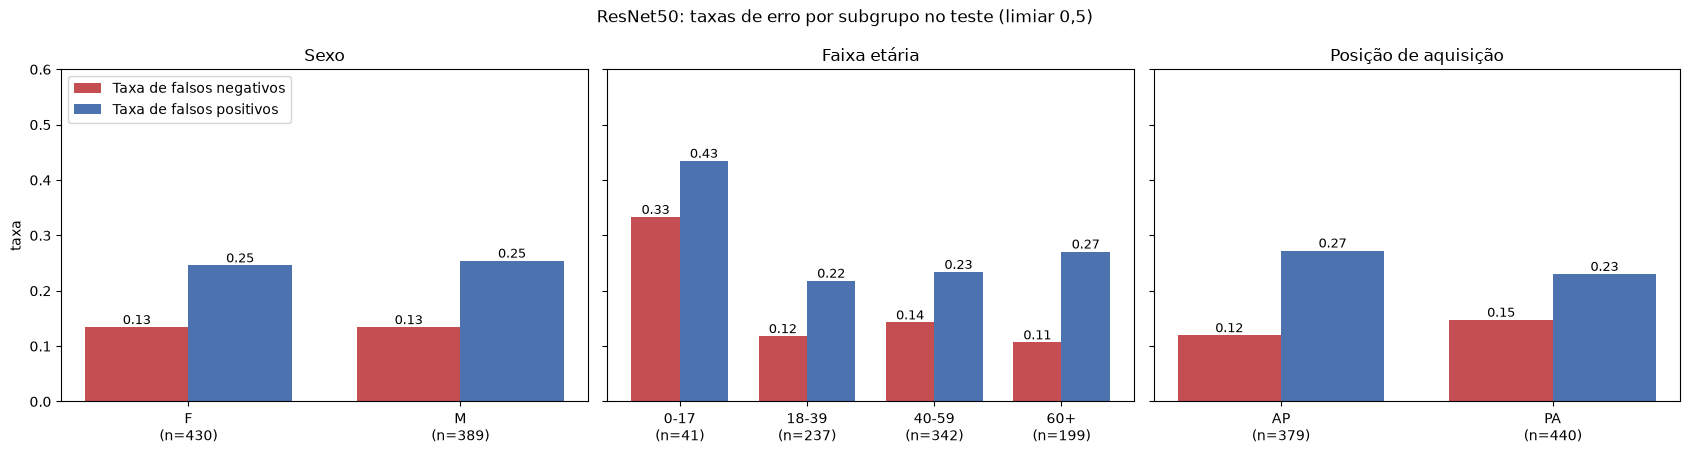

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for a_, atr in zip(ax, ["sexo", "faixa", "visao"]):
    ms = por_grupo[atr]; g = list(ms); x = np.arange(len(g)); w = 0.38
    b1 = a_.bar(x - w / 2, [ms[k]["fnr"] for k in g], w, label="Taxa de falsos negativos", color="#C44E52")
    b2 = a_.bar(x + w / 2, [ms[k]["fpr"] for k in g], w, label="Taxa de falsos positivos", color="#4C72B0")
    a_.bar_label(b1, fmt="%.2f", fontsize=9); a_.bar_label(b2, fmt="%.2f", fontsize=9)
    a_.set_xticks(x); a_.set_xticklabels([f"{k}\n(n={int((teste[atr] == k).sum())})" for k in g]); a_.set_title({"sexo": "Sexo", "faixa": "Faixa etária", "visao": "Posição de aquisição"}[atr])
ax[0].set_ylabel("taxa"); ax[0].legend(loc="upper left"); ax[0].set_ylim(0, 0.6)
plt.suptitle("ResNet50: taxas de erro por subgrupo no teste (limiar 0,5)"); plt.tight_layout()
plt.savefig(DIR_PRINT / "15_fairness_por_subgrupo.png", dpi=130); plt.show()

### 2.1 O padrão se repete na CNN do zero?

Se a mesma disparidade aparece em dois modelos de arquiteturas diferentes, a origem provável está nos dados e não no modelo.

In [7]:
comp = []
for a in ["sexo", "faixa", "visao"]:
    for nome, d in [("ResNet50", teste), ("CNN do zero", teste_cnn)]:
        for g, s in d.groupby(a):
            m = metricas(s); comp.append({"atributo": a, "grupo": g, "modelo": nome, "recall": round(m["recall"], 3), "FPR": round(m["fpr"], 3), "AUC": round(m["auc"], 3)})
pd.DataFrame(comp).pivot(index=["atributo", "grupo"], columns="modelo", values=["recall", "FPR", "AUC"])

recall                  FPR                  AUC         
modelo         CNN do zero ResNet50 CNN do zero ResNet50 CNN do zero ResNet50
atributo grupo                                                               
faixa    0-17        0.889    0.667       0.261    0.435       0.865    0.659
         18-39       0.787    0.882       0.136    0.218       0.904    0.890
         40-59       0.792    0.857       0.234    0.234       0.863    0.898
         60+         0.845    0.893       0.240    0.271       0.870    0.866
sexo     F           0.785    0.866       0.230    0.246       0.855    0.874
         M           0.829    0.866       0.185    0.254       0.895    0.888
visao    AP          0.802    0.880       0.235    0.273       0.864    0.880
         PA          0.814    0.852       0.191    0.230       0.883    0.883

### 2.2 Quantos pacientes sustentam o resultado da faixa de 0 a 17 anos?

A faixa de 0 a 17 anos tem a maior diferença de recall. Antes de interpretar esse número, convém ver de quantos pacientes vêm as imagens positivas dessa faixa e como os erros se distribuem entre eles, no teste e na validação. Cada linha da tabela é um paciente.

In [8]:
def por_paciente(d, conjunto):
    s = d[(d.faixa == "0-17") & (d.y == 1)].assign(det=lambda x: (x.prob >= LIMIAR).astype(int))
    t = s.groupby("paciente").agg(positivas=("det", "size"), detectadas=("det", "sum"),
                                  probabilidades=("prob", lambda v: "  ".join(f"{p:.2f}" for p in v)))
    t["nao detectadas"] = t.positivas - t.detectadas
    t.insert(0, "conjunto", conjunto)
    return t.sort_values(["positivas", "detectadas"], ascending=False).reset_index(drop=True)

ped = pd.concat([por_paciente(teste, "teste"), por_paciente(val, "validação")], ignore_index=True)
for c in ["teste", "validação"]:
    s = ped[ped.conjunto == c]
    print(f"{c}: {s.positivas.sum()} imagens positivas de {len(s)} pacientes | imagens não detectadas: {s['nao detectadas'].sum()} | pacientes com alguma imagem não detectada: {(s['nao detectadas'] > 0).sum()}")
fn = teste[(teste.faixa == "0-17") & (teste.y == 1) & (teste.prob < LIMIAR)]
print(f"Falsos negativos do teste com probabilidade na faixa inconclusiva do protótipo ({cfg['limiar_sensivel']:.2f} a {LIMIAR:.2f}): {int((fn.prob >= cfg['limiar_sensivel']).sum())} de {len(fn)}")
ped[["conjunto", "positivas", "detectadas", "nao detectadas", "probabilidades"]]

teste: 18 imagens positivas de 6 pacientes | imagens não detectadas: 6 | pacientes com alguma imagem não detectada: 4
validação: 10 imagens positivas de 10 pacientes | imagens não detectadas: 1 | pacientes com alguma imagem não detectada: 1
Falsos negativos do teste com probabilidade na faixa inconclusiva do protótipo (0.41 a 0.50): 3 de 6


,conjunto,positivas,detectadas,nao detectadas,probabilidades
0,teste,7,6,1,0.64 0.91 0.76 0.65 0.45 0.63 0.94
1,teste,4,2,2,0.46 0.63 0.59 0.43
2,teste,3,1,2,0.89 0.25 0.17
3,teste,2,1,1,0.28 0.77
4,teste,1,1,0,0.98
5,teste,1,1,0,0.90
6,validação,1,1,0,0.92
7,validação,1,1,0,0.78
8,validação,1,1,0,0.99
9,validação,1,1,0,0.90


## 3. Experimento de mitigação: limiar por grupo

Uma prática de mitigação de pós-processamento é usar um limiar de decisão diferente por grupo, de modo que o recall fique igual entre eles. O experimento abaixo aplica a ideia ao atributo com a maior disparidade de recall:

1. no conjunto de **validação**, escolhe para cada grupo o maior limiar que atinge o mesmo recall-alvo (o recall global do modelo na validação com limiar 0,5);
2. aplica esses limiares, sem reajuste, ao conjunto de **teste**, e compara com o limiar único.

In [9]:
ATR = resumo["igualdade de oportunidade (dif. recall)"].idxmax()
if ATR == "faixa": ATR = resumo.drop(index="faixa")["igualdade de oportunidade (dif. recall)"].idxmax()   # faixa 0-17 tem amostra pequena demais para calibrar limiar
alvo = metricas(val)["recall"]
cand = np.round(np.arange(0.05, 0.96, 0.01), 2)
lim_g = {}
for g, s in val.groupby(ATR):
    rec = np.array([metricas(s, c)["recall"] for c in cand])
    lim_g[g] = float(cand[rec >= alvo].max())
print(f"Atributo: {ATR} | recall-alvo (validação, limiar 0,5): {alvo:.3f} | limiares por grupo:", lim_g)

antes = {g: metricas(s) for g, s in teste.groupby(ATR)}
depois = {g: metricas(s, lim_g[g]) for g, s in teste.groupby(ATR)}
t_antes, t_depois = metricas(teste), None
yp = np.concatenate([(s.prob.values >= lim_g[g]).astype(int) for g, s in teste.groupby(ATR)]); yy = np.concatenate([s.y.values for g, s in teste.groupby(ATR)])
geral_depois = {"acuracia": (yp == yy).mean(), "recall": yp[yy == 1].mean(), "fpr": yp[yy == 0].mean(), "fn": int(((yy == 1) & (yp == 0)).sum()), "fp": int(((yy == 0) & (yp == 1)).sum())}
ya = (teste.prob.values >= LIMIAR).astype(int)
geral_antes = {"acuracia": (ya == teste.y.values).mean(), "recall": t_antes["recall"], "fpr": t_antes["fpr"], "fn": t_antes["fn"], "fp": t_antes["fp"]}

mit = pd.DataFrame([{"cenario": "limiar único 0,5", **{f"recall {g}": round(antes[g]["recall"], 3) for g in antes}, **{f"FPR {g}": round(antes[g]["fpr"], 3) for g in antes},
                     "dif. recall": round(max(v["recall"] for v in antes.values()) - min(v["recall"] for v in antes.values()), 3),
                     "dif. FPR": round(max(v["fpr"] for v in antes.values()) - min(v["fpr"] for v in antes.values()), 3), **{k: round(v, 3) if isinstance(v, float) else v for k, v in geral_antes.items()}},
                    {"cenario": "limiar por grupo", **{f"recall {g}": round(depois[g]["recall"], 3) for g in depois}, **{f"FPR {g}": round(depois[g]["fpr"], 3) for g in depois},
                     "dif. recall": round(max(v["recall"] for v in depois.values()) - min(v["recall"] for v in depois.values()), 3),
                     "dif. FPR": round(max(v["fpr"] for v in depois.values()) - min(v["fpr"] for v in depois.values()), 3), **{k: round(float(v), 3) if not isinstance(v, int) else v for k, v in geral_depois.items()}}]).set_index("cenario")
mit.to_csv(RAIZ / "data" / "fairness_mitigacao.csv")
mit.T

Atributo: visao | recall-alvo (validação, limiar 0,5): 0.853 | limiares por grupo: {'AP': 0.49, 'PA': 0.5}


cenario,"limiar único 0,5",limiar por grupo
recall AP,0.880,0.880
recall PA,0.852,0.852
FPR AP,0.273,0.278
FPR PA,0.230,0.230
dif. recall,0.028,0.028
dif. FPR,0.042,0.048
acuracia,0.807,0.806
recall,0.866,0.866
fpr,0.249,0.252
fn,54.000,54.000


### 3.1 A disparidade por faixa etária se repete na validação? E a média dos dois modelos ajuda?

O conjunto de validação tem pacientes diferentes dos do teste. Se a diferença observada no teste para a faixa de 0 a 17 anos for um efeito real do modelo, ela deve aparecer também ali, com a ressalva de que a validação orientou a escolha dos pesos e por isso tende a ser um pouco otimista. A segunda tabela testa, de forma exploratória, uma mitigação simples: usar a **média das probabilidades** da ResNet50 e da CNN do zero.

In [10]:
val_cnn = carregar("val", "cnn_do_zero")
def por_faixa(d, nome):
    return [{"conjunto": nome[0], "modelo": nome[1], "faixa": g, "n": len(s), "positivas": int(s.y.sum()), "recall": round(metricas(s)["recall"], 3),
             "FPR": round(metricas(s)["fpr"], 3), "AUC": round(metricas(s)["auc"], 3)} for g, s in d.groupby("faixa")]
def media(a, b):
    m = a.merge(b[["arquivo", "prob"]], on="arquivo", suffixes=("", "_b")); m["prob"] = (m.prob + m.prob_b) / 2; return m
linhas = []
for conj, r, c in [("validação", val, val_cnn), ("teste", teste, teste_cnn)]:
    linhas += por_faixa(r, (conj, "ResNet50")) + por_faixa(c, (conj, "CNN do zero")) + por_faixa(media(r, c), (conj, "média dos dois"))
rep_f = pd.DataFrame(linhas)
rep_f.to_csv(RAIZ / "data" / "fairness_faixa_replicacao.csv", index=False)
print(rep_f.pivot(index=["conjunto", "faixa", "n", "positivas"], columns="modelo", values=["recall", "AUC"]).to_string())
ens = media(teste, teste_cnn); g = metricas(ens)
print(f"\nMédia dos dois modelos, teste completo: recall {g['recall']:.3f} | FPR {g['fpr']:.3f} | AUC {g['auc']:.3f} | FN {g['fn']} | FP {g['fp']}")

                                   recall                                 AUC                        
modelo                        CNN do zero ResNet50 média dos dois CNN do zero ResNet50 média dos dois
conjunto  faixa n   positivas                                                                        
teste     0-17  41  18              0.889    0.667          0.778       0.865    0.659          0.819
          18-39 237 127             0.787    0.882          0.866       0.904    0.890          0.913
          40-59 342 154             0.792    0.857          0.838       0.863    0.898          0.894
          60+   199 103             0.845    0.893          0.903       0.870    0.866          0.883
validação 0-17  30  10              0.900    0.900          1.000       0.845    0.890          0.960
          18-39 219 101             0.782    0.891          0.871       0.899    0.927          0.932
          40-59 331 152             0.770    0.855          0.868       0.886    0

## 4. Análise e implicações éticas

Todos os números vêm da execução gravada neste notebook (ResNet50, 819 imagens de teste de 652 pacientes, limiar 0,5), exceto os do parágrafo sobre o segundo treino, que vêm do registro `docs/teste_colab_2026-11-20.md`.

### Limitações do dataset

- **Desbalanceamento de origem.** A Cardiomegalia aparece em 2,48% das 112.120 imagens. O subconjunto balanceado (50%) viabilizou o treino, mas as métricas não valem para a prevalência real.
- **Representatividade.** O dataset tem 56,5% de imagens de homens e 43,5% de mulheres. Crianças e adolescentes (0 a 17 anos) são 4,8% das imagens. A prevalência do rótulo é maior em mulheres (3,01%) que em homens (2,06%) e maior em AP (2,71%) que em PA (2,32%).
- **Atributos ausentes.** Não há raça, etnia nem condição socioeconômica, o que impede medir viés nessas dimensões. Todas as imagens vêm de um único hospital dos Estados Unidos.
- **Rótulos com ruído**, extraídos automaticamente dos laudos.
- **Poucos pacientes em alguns grupos.** As 402 imagens positivas do teste vêm de 235 pacientes. Na faixa de 0 a 17 anos são 18 imagens positivas de apenas 6 pacientes.

### O que as métricas de fairness mostram

| Atributo | Diferença de recall | p | Diferença de FPR | p | Paridade demográfica | Leitura |
|---|---|---|---|---|---|---|
| Sexo | 0,000 | 1,00 | 0,008 | 0,91 | 0,080 | Sem disparidade nas taxas de erro |
| Posição de aquisição | 0,028 | 0,74 | 0,042 | 0,36 | 0,053 | Sem disparidade detectável |
| Faixa etária | 0,227 | 0,012 | 0,217 | 0,052 | 0,078 | Sinal de alerta na faixa de 0 a 17 anos, inconclusivo (6 pacientes) |

Os valores p são os do esquema estratificado. No esquema simples eles são 1,00 e 0,85 (sexo), 0,47 e 0,33 (posição de aquisição) e 0,046 e 0,082 (faixa etária). A diferença de odds equalizadas é a maior das duas diferenças de cada linha: 0,008, 0,042 e 0,227.

- **Sexo.** O recall é idêntico (86,6% em mulheres e em homens) e a taxa de falsos positivos é praticamente igual (24,6% e 25,4%). A precisão é menor em mulheres (72,9% contra 81,0%) porque há proporcionalmente menos casos positivos femininos no teste (43,3% das imagens de mulheres, contra 55,5% das de homens), e não porque o modelo erre mais. A diferença de paridade demográfica (0,080) tem a mesma origem: com taxas de erro iguais, o grupo com mais casos positivos recebe mais resultados positivos.
- **Posição de aquisição.** Recall de 88,0% em AP e 85,2% em PA, com intervalos de confiança sobrepostos. O pareamento por posição feito na Parte 1 cumpriu o objetivo: o modelo não ficou dependente desse atributo. Em 27 dos 652 pacientes do teste (116 imagens) há imagens nas duas posições, e por isso o esquema estratificado, que mantém a posição de cada imagem, é o adequado para este atributo.
- **Faixa etária.** Nas três faixas adultas o recall fica entre 85,7% e 89,3%. Na faixa de 0 a 17 anos ele cai para 66,7% (6 falsos negativos em 18 casos) e o AUC para 0,659, com 43,5% de falsos positivos.

### O achado pediátrico é real?

Os dados não permitem afirmar nem descartar.

A favor de um efeito real:

1. **O teste estratificado.** Quando cada paciente é comparado com pacientes da mesma classe e com o mesmo número de imagens, a diferença de recall tem valor p de 0,012 (0,046 no esquema simples). Foram feitas seis comparações (três atributos e duas métricas): o valor fica abaixo do limite de Bonferroni para três comparações (0,017) e acima do limite para seis (0,008).
2. **Os dois tipos de erro pioram juntos.** A faixa de 0 a 17 anos tem também a maior taxa de falsos positivos (43,5%, p = 0,052) e o menor AUC (0,659).
3. **Há um motivo plausível, não testado aqui.** O modelo viu poucas radiografias pediátricas (a faixa de 0 a 17 anos é 4,8% do dataset), e o tórax da criança difere do adulto em tamanho e proporções.

Contra tratá-lo como fato estabelecido:

1. **Poucos pacientes.** As 18 imagens positivas vêm de apenas 6 pacientes, e os 6 falsos negativos, de 4 deles, todos com mais de uma imagem no teste. Somando teste e validação, 11 dos 12 pacientes dessa faixa com uma única imagem positiva foram detectados. O intervalo de confiança do recall vai de 42,9% a 88,2%.
2. **Não se repete na validação.** Na validação há 10 imagens positivas dessa faixa, de 10 pacientes diferentes dos do teste, e 9 foram detectadas (recall de 90,0%, AUC de 0,890). A ressalva é que a validação orientou a escolha dos pesos do modelo, portanto é uma checagem menos isenta que o teste.
3. **Não aparece na CNN do zero**, que nas mesmas imagens de teste teve recall de 88,9% e AUC de 0,865. Isso sugere que, se o efeito existir, é específico da ResNet50 e não dos dados.

O esquema estratificado também tem um limite: os 6 pacientes com 7 ou mais imagens (61 imagens) não têm outro paciente com o mesmo número de imagens e ficam fixos no teste. Um deles é o paciente pediátrico com 7 imagens.

Três dos seis falsos negativos da faixa têm probabilidade entre 0,43 e 0,46 e caem na zona inconclusiva do protótipo (41% a 50%), em que a tela recomenda revisão por um médico. A conclusão responsável é registrar o risco: **o desempenho em pacientes pediátricos não está validado**.

**Segundo treino (Google Colab).** Os dois modelos foram treinados de novo no Google Colab, com o mesmo código e a mesma semente, em outro hardware. A ResNet50 repetiu o padrão nas mesmas imagens de teste: recall de 50,0% e AUC de 0,664 na faixa de 0 a 17 anos, com valor p de 0,003 no esquema estratificado e 0,006 no simples. A CNN do zero voltou a não mostrar a queda (88,9% e 0,872). Na validação, a ResNet50 detectou 8 das 10 imagens positivas da faixa, com AUC de 0,895. A taxa de falsos positivos da faixa no teste foi de 26,1%, sem diferença para as demais (p = 0,66). O segundo treino mostra que a queda de recall não é exclusiva de uma execução, mas não resolve a limitação principal: os pacientes são os mesmos 6, e a semente também é a mesma.

### Experimentos de mitigação

- **Limiar por grupo (posição de aquisição).** Os limiares calibrados na validação ficaram em 0,49 para AP e 0,50 para PA, e o resultado no teste praticamente não mudou (um falso positivo a mais). O experimento confirma que não havia disparidade a corrigir nesse atributo. Para a faixa de 0 a 17 anos a técnica não é aplicável: com 10 casos positivos na validação, qualquer limiar calibrado seria ruído.
- **Média dos dois modelos (exploratório).** A média das probabilidades da ResNet50 e da CNN do zero elevou o AUC no teste de 0,882 para 0,894 e reduziu os falsos positivos de 104 para 88, com 56 falsos negativos (contra 54). Na faixa de 0 a 17 anos o AUC foi de 0,659 para 0,819. Como essa combinação foi testada depois de ver os resultados do teste, o ganho precisa ser confirmado em dados novos antes de ser adotado.

### Implicações éticas e práticas de mitigação recomendadas

1. **Restringir o uso declarado.** O protótipo deve informar que não foi validado para menores de 18 anos. É a mitigação mais barata e a mais honesta.
2. **Coletar mais dados dos grupos sub-representados**, em especial pediátricos, e de outros hospitais, antes de qualquer uso além do acadêmico.
3. **Auditar por subgrupo de forma contínua**, com tamanho mínimo de amostra por grupo definido de antemão e contado em pacientes, não em imagens. Uma métrica global boa (AUC de 0,882) esconde grupos em que o modelo pode falhar.
4. **Manter revisão humana.** A zona inconclusiva do protótipo e o aviso de uso acadêmico existem porque o falso negativo é o erro mais grave e não se distribui necessariamente de forma igual.
5. **Documentar o que não foi medido.** Raça, etnia e condição socioeconômica não constam do dataset. Um sistema real exigiria esses dados, tratados conforme a LGPD, para que a equidade pudesse ser verificada.
6. **Não ler igualdade de métricas como ausência de viés.** Os rótulos vêm de laudos. Se um grupo for sistematicamente sub ou superdiagnosticado nos laudos, o modelo reproduz esse padrão e as métricas calculadas contra os mesmos rótulos não o revelam.